In [3]:
import os
from PIL import Image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam

tf.random.set_seed(42)
np.random.seed(42) 

In [4]:
DATA_DIR=r"D:\dl-workspace\notebooks\datasets\Pneumonia X Ray"
print(os.listdir(DATA_DIR))

['chest_xray', 'test', 'train', 'val', '__MACOSX']


In [6]:
for root, dirs, files in os.walk(DATA_DIR):
    print(root ,"->",len(files),"files")

D:\dl-workspace\notebooks\datasets\Pneumonia X Ray -> 0 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray -> 1 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\test -> 1 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\test\NORMAL -> 234 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\test\PNEUMONIA -> 390 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\train -> 1 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\train\NORMAL -> 1342 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\train\PNEUMONIA -> 2954 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\val -> 1 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\val\NORMAL -> 9 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\chest_xray\val\PNEUMONIA -> 9 files
D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\test -> 0 files
D:\dl-workspace\notebooks\datasets\

In [31]:
TRAIN_DIR=r"D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\train"
TEST_DIR=r"D:\dl-workspace\notebooks\datasets\Pneumonia X Ray\test"

IMG_SIZE=(128,128)
BATCH=32

train_ds=keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.1,
    image_size=IMG_SIZE,
    batch_size=BATCH,
    subset="training",
    seed=42,
    label_mode="int"
)
val_ds=keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.1,
    image_size=IMG_SIZE,
    batch_size=BATCH,
    subset="validation",
    seed=42,
    label_mode="int"
)
test_ds=keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH,
    shuffle=False,
    label_mode="int"
)

Found 3937 files belonging to 2 classes.
Using 3544 files for training.
Found 3937 files belonging to 2 classes.
Using 393 files for validation.
Found 624 files belonging to 2 classes.


In [32]:
class_names=train_ds.class_names
num_classes=len(class_names)
print(num_classes)
print(class_names)

2
['NORMAL', 'PNEUMONIA']


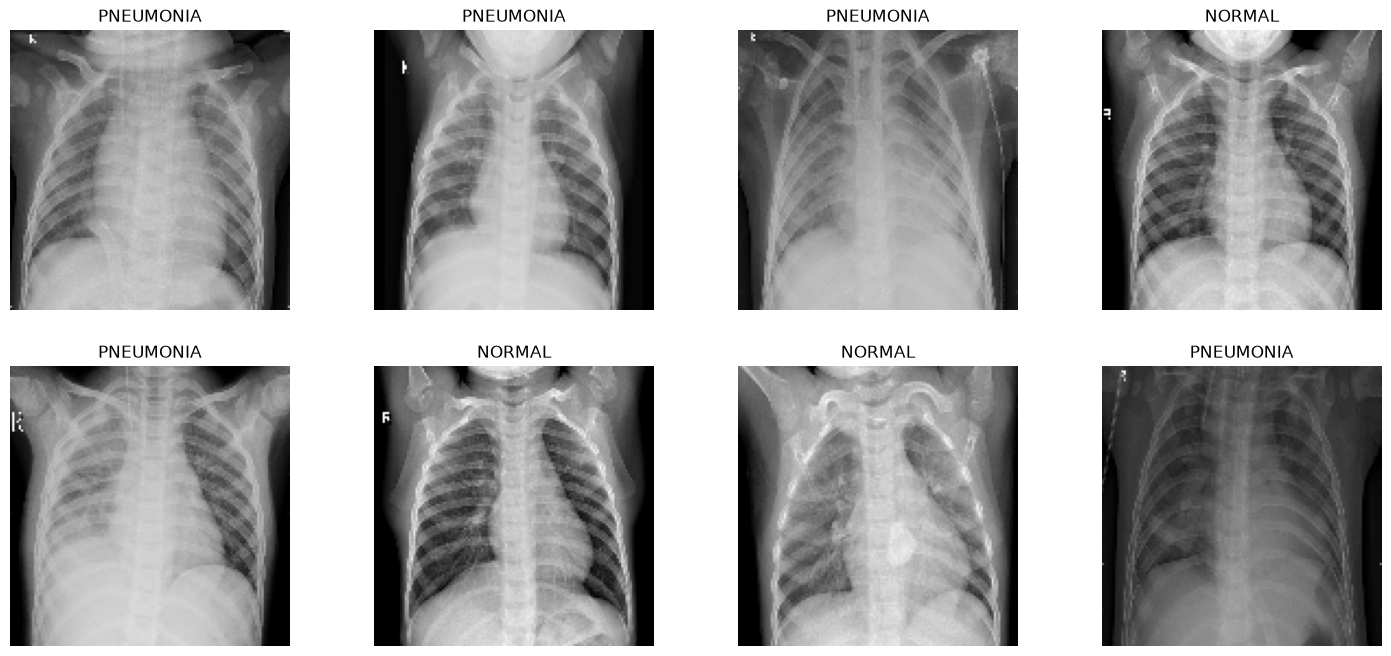

In [33]:
plt.figure(figsize=(18,8))

for images,labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2,4,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")
plt.show()

In [34]:
model=keras.Sequential([
    layers.Input(shape=(128,128,3)),
    layers.Rescaling(1.0/255.0),
    
    layers.Conv2D(32,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1,activation="sigmoid")
])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model.compile(
    loss="binary_crossentropy",
    optimizer=Adam(learning_rate=0.001),
    metrics=["accuracy"]
)
history=model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    verbose=1
)

Epoch 1/15


d:\dl-workspace\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


111/111 ━━━━━━━━━━━━━━━━━━━━ 22s 180ms/step - accuracy: 0.8496 - loss: 0.3377 - val_accuracy: 0.9211 - val_loss: 0.1745
Epoch 2/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 33s 292ms/step - accuracy: 0.9540 - loss: 0.1283 - val_accuracy: 0.9389 - val_loss: 0.1568
Epoch 3/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 25s 229ms/step - accuracy: 0.9608 - loss: 0.1073 - val_accuracy: 0.9491 - val_loss: 0.1326
Epoch 4/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 26s 234ms/step - accuracy: 0.9704 - loss: 0.0798 - val_accuracy: 0.9567 - val_loss: 0.1283
Epoch 5/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 29s 256ms/step - accuracy: 0.9766 - loss: 0.0638 - val_accuracy: 0.9796 - val_loss: 0.0784
Epoch 6/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 30s 273ms/step - accuracy: 0.9777 - loss: 0.0613 - val_accuracy: 0.9771 - val_loss: 0.0900
Epoch 7/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 35s 313ms/step - accuracy: 0.9834 - loss: 0.0475 - val_accuracy: 0.9517 - val_loss: 0.1398
Epoch 8/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 41s 371ms/step - accuracy: 0.9876 - loss: 0.0368 - val

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.7997 - loss: 1.4103
1.410268783569336
0.7996794581413269
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step
              precision    recall  f1-score   support

           0       0.96      0.49      0.65       234
           1       0.76      0.99      0.86       390

    accuracy                           0.80       624
   macro avg       0.86      0.74      0.75       624
weighted avg       0.84      0.80      0.78       624



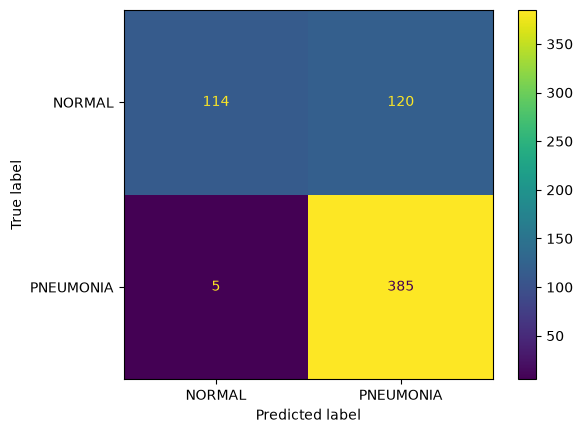

In [37]:
test_loss, test_acc=model.evaluate(test_ds)
print(test_loss)
print(test_acc)

y_true=np.concatenate([y.numpy() for x,y in test_ds]).ravel().astype(int)
y_prob=model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_true,y_pred))
ConfusionMatrixDisplay.from_predictions(y_true,y_pred,display_labels=class_names)

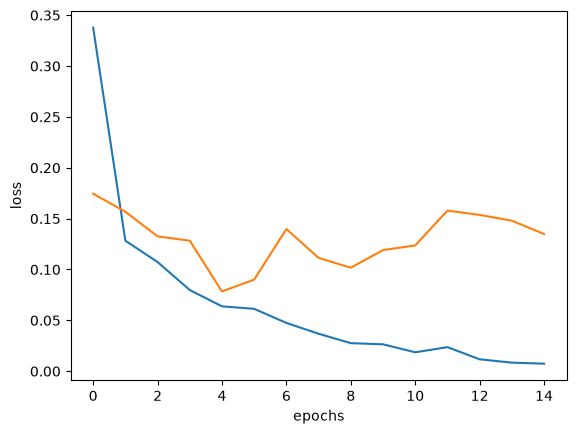

In [38]:
plt.plot(history.history["loss"],label="train loss")
plt.plot(history.history["val_loss"],label="val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.show()